# 04 — Anomaly Detection & Cluster Analysis

**Goal:** Detect anomalous windows using z-scores, build binary activation profiles, discover recurring patterns via hierarchical clustering, and statistically analyze each cluster.

**Depends on:** NB02 (windowed feature datasets)

In [1]:
import sys, os, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, os.path.abspath('..'))
ROOT = os.path.abspath('..')
OUT_DIR = os.path.join(ROOT, 'outputs')

# Load supervised datasets
train_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'train.parquet'))
test_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'test.parquet'))
train_sup['window_end'] = pd.to_datetime(train_sup['window_end'])
test_sup['window_end'] = pd.to_datetime(test_sup['window_end'])

# Drop _sum features: redundant with _mean (r=0.89, see NB03 §6b)
all_feature_cols = [c for c in train_sup.columns if c not in {'timestamp', 'window_end', 'label'}]
feature_cols = [c for c in all_feature_cols if not c.endswith('_sum')]
n_dropped = len(all_feature_cols) - len(feature_cols)
print(f'Dropped {n_dropped} _sum features (redundant with _mean, see NB03 §6b)')

# Combine train+test
train_sup['split'] = 'train'
test_sup['split'] = 'test'
all_sup = pd.concat([train_sup, test_sup], ignore_index=True).sort_values('window_end').reset_index(drop=True)
del train_sup, test_sup; gc.collect()

# Subsystem mapping
def get_subsystem(name):
    name_upper = name.upper()
    if 'DAYS_SINCE' in name_upper:
        return 'Asset'
    if 'MAIN_RESERVOIR' in name_upper or 'COMPRESSOR' in name_upper:
        return 'APU'
    if 'LOAD_PRESSURE' in name_upper or 'LOAD_SIGNAL' in name_upper:
        return 'Leveling'
    if 'ENERGY_BRAKING' in name_upper:
        return 'Traction'
    if 'SPEED' in name_upper or 'TEMPERATURE' in name_upper:
        return 'Context'
    return 'Brake'

feat_subsystem = {f: get_subsystem(f) for f in feature_cols}

SPLIT_DATE = pd.Timestamp('2025-02-12')
print(f'Total windows: {len(all_sup):,} | Features: {len(feature_cols)}')
print(f'Failure windows: {all_sup["label"].sum()} ({100*all_sup["label"].mean():.2f}%)')

Dropped 74 _sum features (redundant with _mean, see NB03 §6b)


Total windows: 64,522 | Features: 266
Failure windows: 1202 (1.86%)


In [2]:
# Quick dataset preview
print(f'Shape: {all_sup.shape[0]:,} windows x {len(feature_cols)} features')
print(f'Time range: {all_sup["window_end"].min()} to {all_sup["window_end"].max()}')
print(f'Label distribution: {all_sup["label"].value_counts().to_dict()}')
print()

# Pick one representative sensor and show all its aggregation types
sample_sensor = 'MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1'
sample_feats = [f for f in feature_cols if f.startswith(sample_sensor)]
preview_cols = ['window_end', 'label', 'split'] + sample_feats
print(f'First 5 rows — example sensor: {sample_sensor}')
all_sup[preview_cols].head()

Shape: 64,522 windows x 266 features
Time range: 2024-06-01 04:41:40 to 2025-07-01 00:04:10
Label distribution: {0: 63320, 1: 1202}

First 5 rows — example sensor: MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1


,window_end,label,split,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_mean
0,2024-06-01 04:41:40,0,train,0.300171,0.552246,0.334786
1,2024-06-01 04:47:30,0,train,0.298096,0.549805,0.463033
2,2024-06-01 04:53:20,0,train,0.004089,0.304199,0.231601
3,2024-06-01 04:59:10,0,train,0.299316,0.548950,0.302646
4,2024-06-01 05:05:00,0,train,0.003723,0.549377,0.309690


## 1. Identify Anomalous Windows

For each window, compute a per-feature z-score (relative to the training normal distribution). A window is "anomalous" if multiple features exceed a z-score threshold.

This is independent of the RF model â€” it's a simple statistical test: *"Is this window unusual compared to normal operation?"*

Z-score threshold: |z| > 3.0
Min activated features: 5

Anomalous windows: 12022 / 64522 (18.6%)
  With failure label: 724 (6.0%)
  Without failure label: 11298 (94.0%)

For comparison:
  Total failure windows: 1202
  Failure windows that are anomalous: 724 (60.2%)


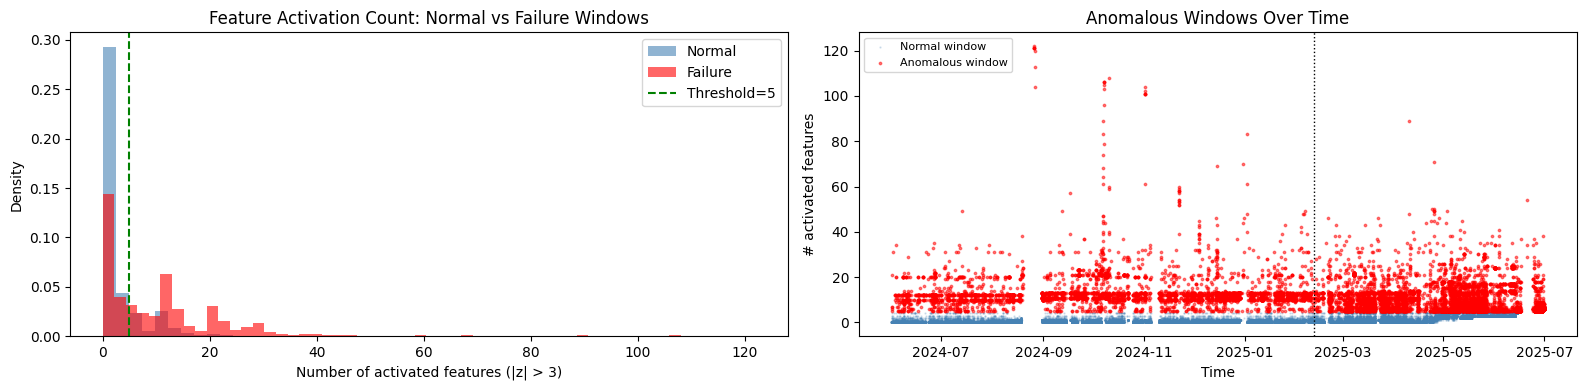

In [3]:
# Compute z-scores relative to train-normal distribution
train_normal = all_sup[(all_sup['split'] == 'train') & (all_sup['label'] == 0)]
feat_means = train_normal[feature_cols].mean()
feat_stds = train_normal[feature_cols].std()
feat_stds = feat_stds.replace(0, 1)  # avoid division by zero
del train_normal; gc.collect()

# Z-score all windows
Z_THRESH = 3.0  # a feature is "activated" if |z| > 3
zscores = (all_sup[feature_cols] - feat_means) / feat_stds
activations = (zscores.abs() > Z_THRESH).astype(int)  # binary: 1 = anomalous feature

# Count activated features per window
all_sup['n_activated'] = activations.sum(axis=1)

# A window is "anomalous" if >= 5 features are activated
MIN_ACTIVATED = 5
all_sup['is_anomalous'] = (all_sup['n_activated'] >= MIN_ACTIVATED).astype(int)

n_anom = all_sup['is_anomalous'].sum()
n_anom_fail = all_sup.loc[all_sup['is_anomalous'] == 1, 'label'].sum()
n_anom_normal = n_anom - n_anom_fail

print(f'Z-score threshold: |z| > {Z_THRESH}')
print(f'Min activated features: {MIN_ACTIVATED}')
print(f'\nAnomalous windows: {n_anom} / {len(all_sup)} ({100*n_anom/len(all_sup):.1f}%)')
print(f'  With failure label: {n_anom_fail} ({100*n_anom_fail/max(n_anom,1):.1f}%)')
print(f'  Without failure label: {n_anom_normal} ({100*n_anom_normal/max(n_anom,1):.1f}%)')
print(f'\nFor comparison:')
print(f'  Total failure windows: {all_sup["label"].sum()}')
print(f'  Failure windows that are anomalous: {n_anom_fail} ({100*n_anom_fail/max(all_sup["label"].sum(),1):.1f}%)')

# Distribution of n_activated
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

ax = axes[0]
ax.hist(all_sup.loc[all_sup['label']==0, 'n_activated'], bins=50, alpha=0.6, color='steelblue', label='Normal', density=True)
ax.hist(all_sup.loc[all_sup['label']==1, 'n_activated'], bins=50, alpha=0.6, color='red', label='Failure', density=True)
ax.axvline(MIN_ACTIVATED, color='green', linestyle='--', label=f'Threshold={MIN_ACTIVATED}')
ax.set_xlabel('Number of activated features (|z| > 3)')
ax.set_ylabel('Density')
ax.set_title('Feature Activation Count: Normal vs Failure Windows')
ax.legend()

ax = axes[1]
ax.scatter(all_sup.loc[all_sup['is_anomalous']==0, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==0, 'n_activated'],
           s=0.5, alpha=0.2, c='steelblue', label='Normal window')
ax.scatter(all_sup.loc[all_sup['is_anomalous']==1, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==1, 'n_activated'],
           s=3, alpha=0.5, c='red', label='Anomalous window')
ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('# activated features')
ax.set_title('Anomalous Windows Over Time')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

## 2. Feature Activation Profiles

For each anomalous window, we have a binary vector: which of the 340 features are activated (|z| > 3)?

This is the "fingerprint" of each anomaly â€” which sensors are behaving unusually.

In [4]:
# Extract activation profiles for anomalous windows only
anom_mask = all_sup['is_anomalous'] == 1
anom_orig_idx = all_sup.index[anom_mask]  # original indices into all_sup
anom_activations = activations.loc[anom_mask].reset_index(drop=True)
anom_meta = all_sup.loc[anom_mask, ['window_end', 'label', 'split', 'n_activated']].reset_index(drop=True)

print(f'Anomalous windows: {len(anom_activations)}')
print(f'Activation matrix shape: {anom_activations.shape}')

# Which features are most commonly activated?
feat_freq = anom_activations.sum().sort_values(ascending=False)
feat_freq_pct = (feat_freq / len(anom_activations) * 100).round(1)

print(f'\nTop 30 most frequently activated features:')
top30 = feat_freq.head(30)
for f, count in top30.items():
    pct = count / len(anom_activations) * 100
    print(f'  {f:55s} {count:5d} ({pct:5.1f}%)')

# Never-activated features
never_activated = (feat_freq == 0).sum()
print(f'\nFeatures never activated: {never_activated} / {len(feature_cols)}')

Anomalous windows: 12022
Activation matrix shape: (12022, 266)

Top 30 most frequently activated features:
  MW4_LOAD_SIGNAL_min                                      3925 ( 32.6%)
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                   3644 ( 30.3%)
  MW4_ENERGY_BRAKING_RESISTANCE_max                        3471 ( 28.9%)
  MW4_ENERGY_BRAKING_RESISTANCE_mean                       3468 ( 28.8%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3258 ( 27.1%)
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3053 ( 25.4%)
  MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3019 ( 25.1%)
  MW4_ENERGY_BRAKING_RESISTANCE_min                        2885 ( 24.0%)
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   2676 ( 22.3%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   2661 ( 22.1%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   2653 ( 22.1%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   2649 ( 22.0%)
  CW2_BRAKE_CYLIN

In [5]:
# ── Deeper look: which activated features are actually failure-relevant? ──

# For each feature: how often does it fire in failure vs normal anomalous windows?
fail_anom = anom_meta['label'] == 1
norm_anom = anom_meta['label'] == 0

baseline_rate = 100 * fail_anom.mean()
top30_feats = feat_freq.head(30).index.tolist()

print(f'{"Feature":<55} {"Total":>6} {"In Fail":>8} {"In Norm":>8} {"Fail Rate":>10}')
print('=' * 95)
for f in top30_feats:
    total = int(anom_activations[f].sum())
    in_fail = int(anom_activations.loc[fail_anom, f].sum())
    in_norm = int(anom_activations.loc[norm_anom, f].sum())
    fail_rate = 100 * in_fail / max(total, 1)
    marker = ' ***' if fail_rate > baseline_rate else ''
    print(f'{f:<55} {total:>6} {in_fail:>8} {in_norm:>8} {fail_rate:>9.1f}%{marker}')

print()
print(f'*** = failure rate > {baseline_rate:.1f}% baseline (more predictive than chance)')

Feature                                                  Total  In Fail  In Norm  Fail Rate
MW4_LOAD_SIGNAL_min                                       3925      398     3527      10.1% ***
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                    3644      265     3379       7.3% ***
MW4_ENERGY_BRAKING_RESISTANCE_max                         3471      220     3251       6.3% ***
MW4_ENERGY_BRAKING_RESISTANCE_mean                        3468      226     3242       6.5% ***
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                    3258      153     3105       4.7%
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                    3053      143     2910       4.7%
MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                    3019      138     2881       4.6%
MW4_ENERGY_BRAKING_RESISTANCE_min                         2885      113     2772       3.9%
CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                    2676      117     2559       4.4%
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                    2661  

In [6]:
# Group by physical sensor (strip _min/_max/_mean/_std/_flips suffix)
print()
print('─' * 60)
print('Aggregated by physical sensor (top 15):')
print('─' * 60)
sensor_info = {}
for f in feat_freq.index:
    for suf in ['_min', '_max', '_mean', '_std', '_flips']:
        if f.endswith(suf):
            sensor = f[:-len(suf)]
            if sensor not in sensor_info:
                sensor_info[sensor] = {'total': 0, 'active_feats': 0, 'all_feats': 0, 'which': []}
            sensor_info[sensor]['total'] += int(feat_freq[f])
            sensor_info[sensor]['all_feats'] += 1
            if int(feat_freq[f]) > 0:
                sensor_info[sensor]['active_feats'] += 1
                sensor_info[sensor]['which'].append(suf[1:])  # strip leading _
            break

sorted_sensors = sorted(sensor_info.items(), key=lambda x: x[1]['total'], reverse=True)
print(f'{"Sensor":<45} {"Activations":>12} {"Active/Total":>13}  Which')
print('-' * 95)
for sensor, info in sorted_sensors[:15]:
    which_str = ', '.join(info['which'])
    print(f'{sensor:<45} {info["total"]:>12} {info["active_feats"]:>6}/{info["all_feats"]:<6}  {which_str}')


────────────────────────────────────────────────────────────
Aggregated by physical sensor (top 15):
────────────────────────────────────────────────────────────
Sensor                                         Activations  Active/Total  Which
-----------------------------------------------------------------------------------------------
MW4_ENERGY_BRAKING_RESISTANCE                         9824      3/3       max, mean, min
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2                    6282      3/3       max, min, mean
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5883      2/3       max, min
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5684      2/3       max, min
MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5616      2/3       max, min
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2                    5115      2/3       min, max
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2                    5086      2/3       min, max
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5068      2/3 

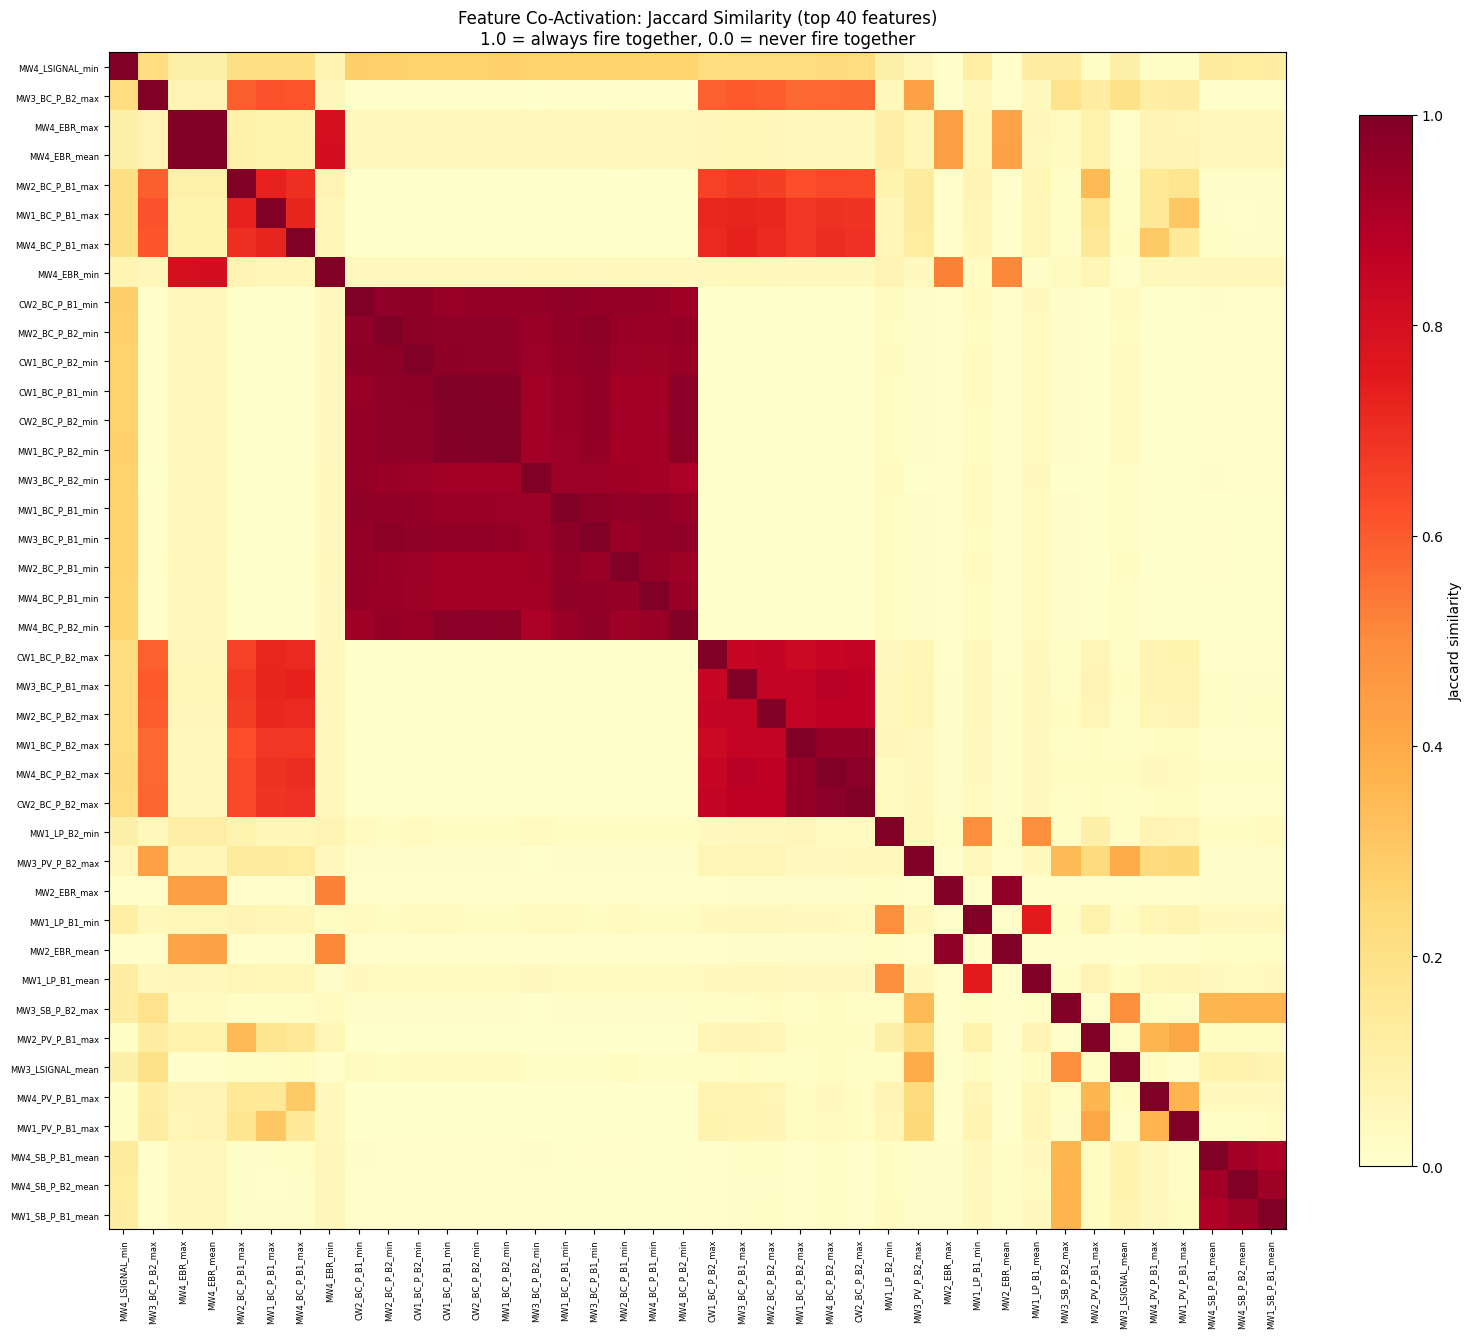

Diagonal = 1.0 (feature with itself)
Off-diagonal bright blocks = features that reliably co-activate
These blocks are what the clustering algorithm discovers automatically.


In [7]:
# ── Option A: Feature Co-Activation Matrix (Jaccard Similarity) ──
# For each pair of features: of the windows where either fires, how often do BOTH fire?
# Jaccard = |A ∩ B| / |A ∪ B|  (0 = never together, 1 = always together)

top40_feats = feat_freq.head(40).index.tolist()
act_matrix = anom_activations[top40_feats].values
n_feats_40 = len(top40_feats)

# Compute pairwise Jaccard similarity
jaccard_sim = np.zeros((n_feats_40, n_feats_40))
for i in range(n_feats_40):
    for j in range(n_feats_40):
        intersection = (act_matrix[:, i] & act_matrix[:, j]).sum()
        union = (act_matrix[:, i] | act_matrix[:, j]).sum()
        jaccard_sim[i, j] = intersection / max(union, 1)

# Short labels for readability
short_labels = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
                .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
                .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
                .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
                for f in top40_feats]

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(jaccard_sim, cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=90, fontsize=6)
ax.set_yticklabels(short_labels, fontsize=6)
ax.set_title('Feature Co-Activation: Jaccard Similarity (top 40 features)\n1.0 = always fire together, 0.0 = never fire together')
plt.colorbar(im, ax=ax, label='Jaccard similarity', shrink=0.8)
plt.tight_layout()
plt.show()

print(f"Diagonal = 1.0 (feature with itself)")
print(f"Off-diagonal bright blocks = features that reliably co-activate")
print(f"These blocks are what the clustering algorithm discovers automatically.")

## 3. Feature Clustering

We cluster **features** (not windows) by their co-activation patterns. Features that consistently fire together across anomalous windows are grouped into **feature clusters (FCs)**. This is the core of our subsystem-aware approach: each FC represents a group of sensors that share a common degradation signature.

In [8]:
# Filter to features that are activated in at least 1% of anomalous windows
min_freq = max(int(len(anom_activations) * 0.01), 2)
active_feats = feat_freq[feat_freq >= min_freq].index.tolist()
print(f'Features activated in >= {min_freq} windows: {len(active_feats)} / {len(feature_cols)}')


Features activated in >= 120 windows: 130 / 266


In [9]:
# ── Heuristic A: Jaccard distance on feature co-activation ──
feat_binary = anom_activations[active_feats].values  # windows x features
feat_dist_jaccard = pdist(feat_binary.T, metric='jaccard')
Z_feat_a = linkage(feat_dist_jaccard, method='average')
feat_labels_a = fcluster(Z_feat_a, t=0.7, criterion='distance')

heuristic_a = {}
for f, cl in zip(active_feats, feat_labels_a):
    heuristic_a.setdefault(int(cl), []).append(f)
n_clusters_a = len(heuristic_a)

# ── Heuristic B: Correlation-based clustering ──
anom_data = all_sup.loc[anom_orig_idx, active_feats]
corr_matrix = anom_data.corr().abs()
corr_dist = 1 - corr_matrix.values
np.fill_diagonal(corr_dist, 0)
corr_dist = np.clip(corr_dist, 0, None)
corr_dist_condensed = squareform(corr_dist)
Z_feat_b = linkage(corr_dist_condensed, method='average')
feat_labels_b = fcluster(Z_feat_b, t=0.5, criterion='distance')

heuristic_b = {}
for f, cl in zip(active_feats, feat_labels_b):
    heuristic_b.setdefault(int(cl), []).append(f)
n_clusters_b = len(heuristic_b)

print(f"Heuristic A (Jaccard): {n_clusters_a} clusters")
print(f"Heuristic B (Correlation): {n_clusters_b} clusters")
print()
print("Heuristic B clusters (top 10 by size):")
for cl_id in sorted(heuristic_b.keys(), key=lambda x: len(heuristic_b[x]), reverse=True)[:10]:
    feats = heuristic_b[cl_id]
    cl_active = anom_activations[feats].any(axis=1)
    n_windows = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_windows, 1)
    sensors = set()
    for f in feats:
        for suffix in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suffix):
                sensors.add(f[:-len(suffix)])
                break
    print(f"  C{cl_id}: {len(feats)} features, {len(sensors)} sensors, {n_windows} windows, {fail_pct:.1f}% failure")

Heuristic A (Jaccard): 31 clusters
Heuristic B (Correlation): 17 clusters

Heuristic B clusters (top 10 by size):
  C11: 41 features, 20 sensors, 3482 windows, 11.3% failure
  C15: 18 features, 18 sensors, 2985 windows, 10.5% failure
  C16: 13 features, 12 sensors, 2794 windows, 4.8% failure
  C17: 10 features, 10 sensors, 4938 windows, 7.7% failure
  C13: 8 features, 3 sensors, 1737 windows, 18.0% failure
  C10: 7 features, 6 sensors, 1411 windows, 8.2% failure
  C14: 6 features, 2 sensors, 3549 windows, 6.9% failure
  C6: 6 features, 2 sensors, 537 windows, 14.7% failure
  C1: 4 features, 4 sensors, 679 windows, 10.6% failure
  C8: 3 features, 1 sensors, 1702 windows, 8.3% failure


In [10]:
# -- All 31 feature clusters (Heuristic A) with details --
print(f'{"FC":>4} {"Feats":>5} {"Sensors":>7} {"Windows":>7} {"Fail%":>6}  Top Features')
print('='*100)

for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    sensors = set()
    for f in feats:
        for suf in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break
    cl_active = anom_activations[feats].any(axis=1)
    n_win = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_win, 1)
    top3 = ', '.join([f[:42] for f in feats[:3]])
    if len(feats) > 3:
        top3 += ', ...'
    print(f'FC{cl_id:>2} {len(feats):>5} {len(sensors):>7} {n_win:>7} {fail_pct:>5.1f}%  {top3}')

# Summary
print()
print('='*60)
print(f'Total: {len(heuristic_a)} feature groups, {sum(len(v) for v in heuristic_a.values())} features')
single = sum(1 for v in heuristic_a.values() if len(v) == 1)
print(f'Single-feature groups: {single}')
print(f'Multi-feature groups: {len(heuristic_a) - single}')

  FC Feats Sensors Windows  Fail%  Top Features
FC 1     4       4     679  10.6%  CW1_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW2_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW1_SPRING_BRAKE_ACTIVE_BOGIE1_flips, ...
FC 2     1       1     490   7.8%  CW1_COMPRESSOR_RUNNING_flips
FC 3     1       1     344  15.4%  CW2_COMPRESSOR_RUNNING_flips
FC 4    10      10    4938   7.7%  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max, MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max, MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max, ...
FC 5     3       3    1876   4.9%  MW2_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max, MW4_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max, MW1_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max
FC 6     4       4    1097  10.2%  MW1_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, MW2_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, MW2_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, ...
FC 7     4       4     259  12.0%  MW3_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, MW4_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, MW4_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, ...
FC 8     3       3     701  

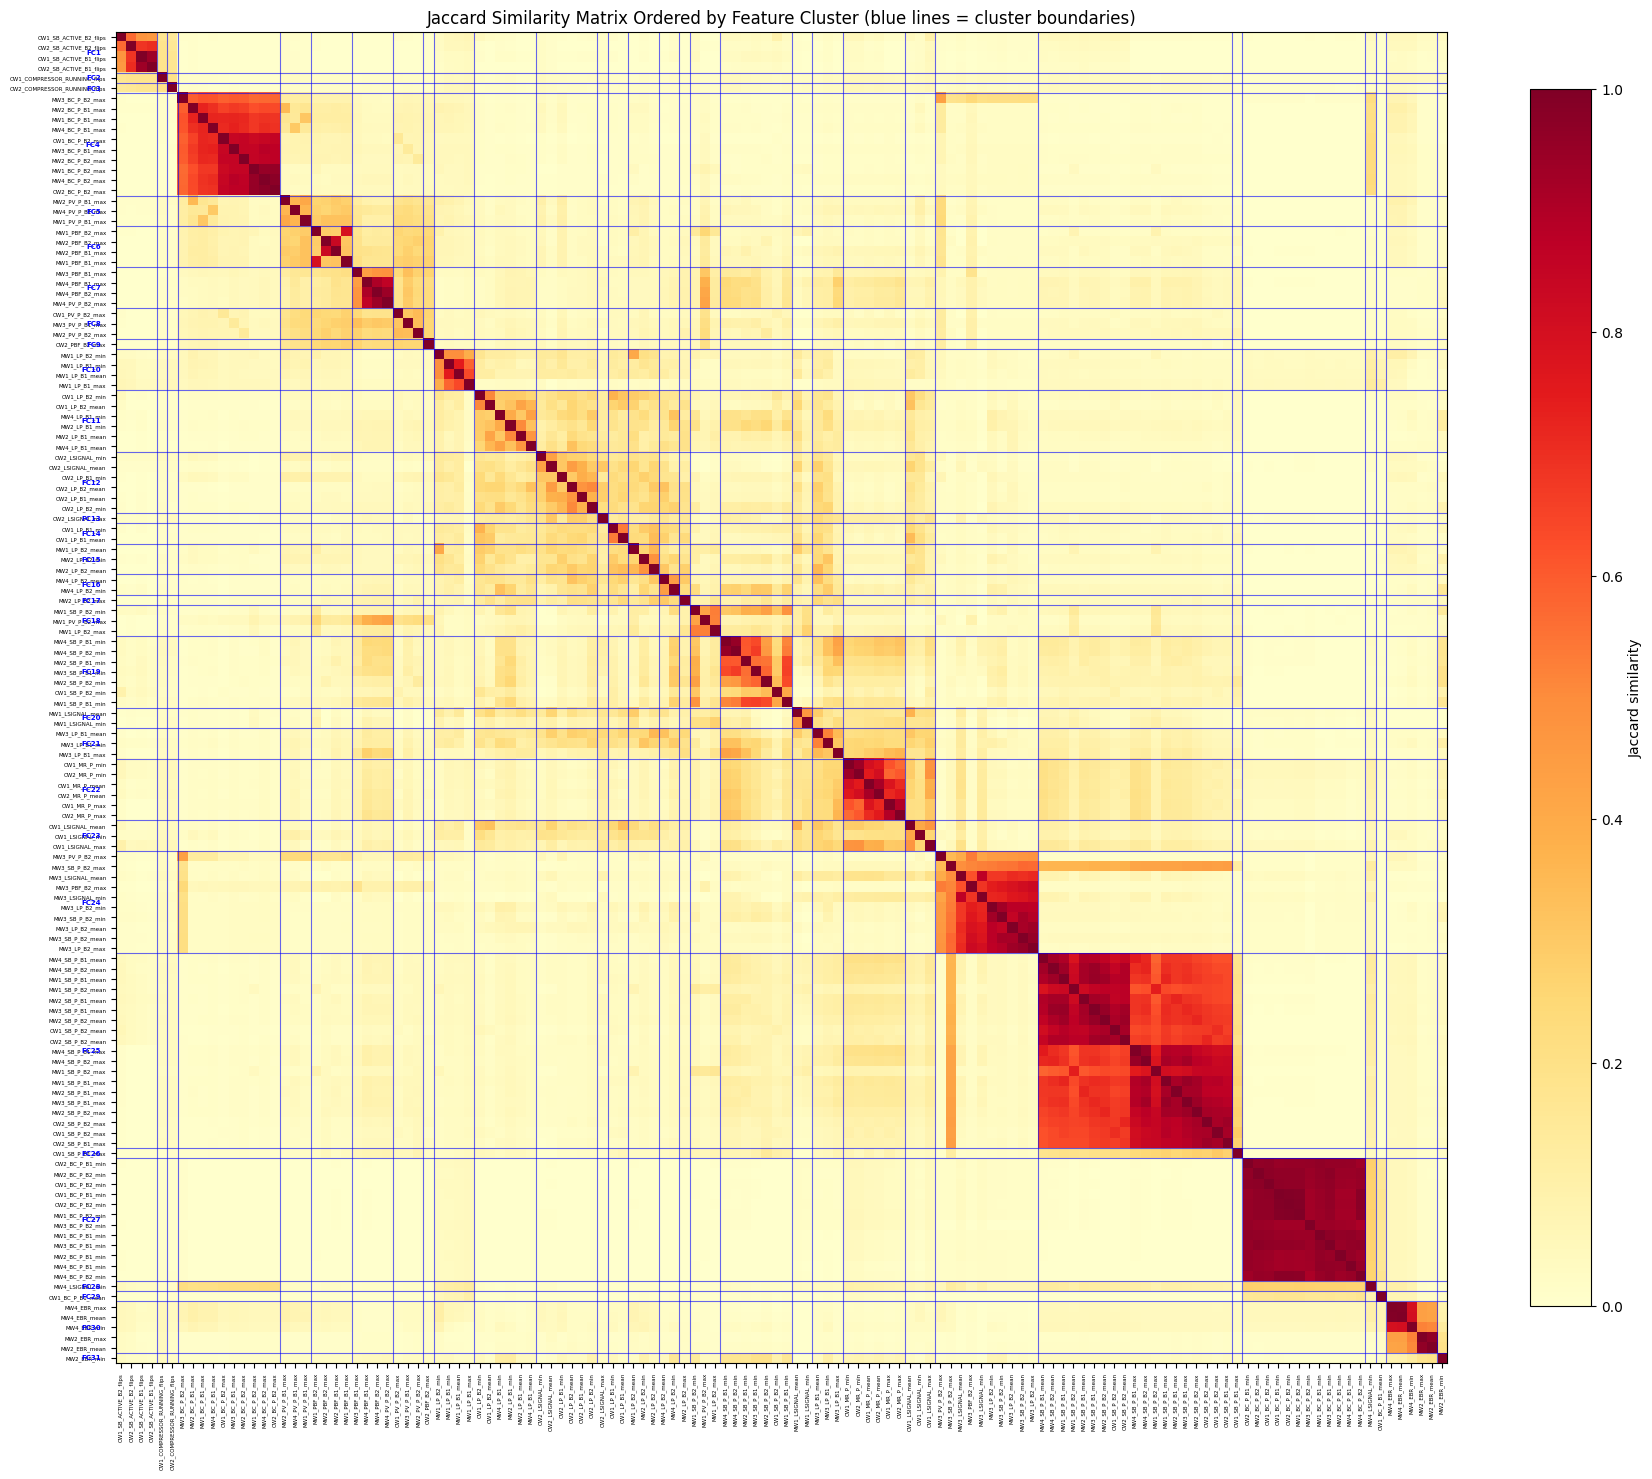

Total features shown: 130
Bright blocks along the diagonal = features within the same cluster co-activate.
Off-diagonal bright spots = clusters that tend to fire together.


In [11]:
# ── Option C: Clustered Co-Activation Heatmap (Jaccard Similarity) ──
# Same Jaccard similarity but reordered by feature cluster assignment
# This reveals the block-diagonal structure that clustering discovered

# Get all active features ordered by cluster
fc_order = []
fc_boundaries = []
pos = 0
for fc in sorted(heuristic_a.keys()):
    feats_active = [f for f in heuristic_a[fc] if f in active_feats]
    if feats_active:
        fc_order.extend(feats_active)
        fc_boundaries.append(pos)
        pos += len(feats_active)

# Compute Jaccard similarity in cluster order
act_ordered = anom_activations[fc_order].values
n_f = act_ordered.shape[0]
n_cols = len(fc_order)

jaccard_ordered = np.zeros((n_cols, n_cols))
for i in range(n_cols):
    for j in range(i, n_cols):
        intersection = (act_ordered[:, i] & act_ordered[:, j]).sum()
        union = (act_ordered[:, i] | act_ordered[:, j]).sum()
        val = intersection / max(union, 1)
        jaccard_ordered[i, j] = val
        jaccard_ordered[j, i] = val

# Short labels
short = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
         .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
         .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
         .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
         for f in fc_order]

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(jaccard_ordered, cmap='YlOrRd', vmin=0, vmax=1)

# Draw cluster boundary lines
for b in fc_boundaries[1:]:
    ax.axhline(b - 0.5, color='blue', linewidth=0.8, alpha=0.6)
    ax.axvline(b - 0.5, color='blue', linewidth=0.8, alpha=0.6)

# Label clusters on the side
fc_idx = 0
for fc in sorted(heuristic_a.keys()):
    feats_active = [f for f in heuristic_a[fc] if f in active_feats]
    if feats_active:
        mid = fc_boundaries[fc_idx] + len(feats_active) / 2 - 0.5
        ax.text(-2, mid, f'FC{fc}', fontsize=5, ha='right', va='center', color='blue', fontweight='bold')
        fc_idx += 1

ax.set_xticks(range(len(short)))
ax.set_yticks(range(len(short)))
ax.set_xticklabels(short, rotation=90, fontsize=4)
ax.set_yticklabels(short, fontsize=4)
ax.set_title('Jaccard Similarity Matrix Ordered by Feature Cluster (blue lines = cluster boundaries)')
plt.colorbar(im, ax=ax, label='Jaccard similarity', shrink=0.8)
plt.tight_layout()
plt.show()

print(f"Total features shown: {len(fc_order)}")
print("Bright blocks along the diagonal = features within the same cluster co-activate.")
print("Off-diagonal bright spots = clusters that tend to fire together.")

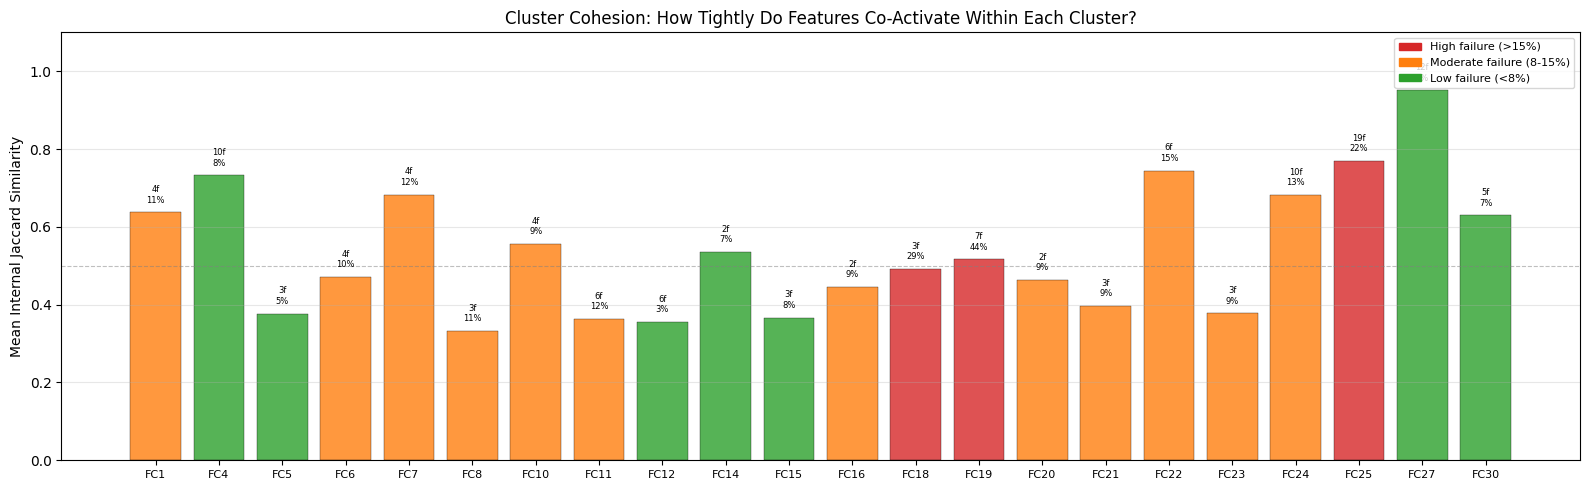

Multi-feature clusters: 22
Mean cohesion: 0.540
Clusters with cohesion > 0.5: 11
Clusters with cohesion > 0.3: 22

Annotation: Nf = number of features, % = failure rate


In [12]:
# ── Cluster Cohesion: Average Internal Jaccard Similarity per FC ──
# For each cluster with >= 2 features, compute the mean pairwise Jaccard similarity

fc_ids_all = sorted(heuristic_a.keys())
fc_labels_plot = []
fc_cohesion = []
fc_sizes = []
fc_fail_pcts = []

for fc in fc_ids_all:
    feats = [f for f in heuristic_a[fc] if f in active_feats]
    if len(feats) < 2:
        continue
    
    act_sub = anom_activations[feats].values
    n = len(feats)
    jac_vals = []
    for i in range(n):
        for j in range(i + 1, n):
            inter = (act_sub[:, i] & act_sub[:, j]).sum()
            union = (act_sub[:, i] | act_sub[:, j]).sum()
            jac_vals.append(inter / max(union, 1))
    
    cl_act = anom_activations[feats].any(axis=1)
    n_win = cl_act.sum()
    n_fail = int(anom_meta.loc[cl_act, 'label'].sum())
    
    fc_labels_plot.append(f'FC{fc}')
    fc_cohesion.append(np.mean(jac_vals))
    fc_sizes.append(len(feats))
    fc_fail_pcts.append(100 * n_fail / max(n_win, 1))

# Plot
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(fc_labels_plot))
colors = ['#d62728' if fp > 15 else '#ff7f0e' if fp > 8 else '#2ca02c' for fp in fc_fail_pcts]
bars = ax.bar(x, fc_cohesion, color=colors, alpha=0.8, edgecolor='black', linewidth=0.3)

# Annotate with size and failure %
for i, (coh, sz, fp) in enumerate(zip(fc_cohesion, fc_sizes, fc_fail_pcts)):
    ax.text(i, coh + 0.02, f'{sz}f\n{fp:.0f}%', ha='center', va='bottom', fontsize=6)

ax.set_xticks(x)
ax.set_xticklabels(fc_labels_plot, fontsize=8)
ax.set_ylabel('Mean Internal Jaccard Similarity')
ax.set_title('Cluster Cohesion: How Tightly Do Features Co-Activate Within Each Cluster?')
ax.set_ylim(0, 1.1)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, label='0.5 threshold')
ax.grid(axis='y', alpha=0.3)

# Legend for colors
from matplotlib.patches import Patch
legend_patches = [
    Patch(color='#d62728', label='High failure (>15%)'),
    Patch(color='#ff7f0e', label='Moderate failure (8-15%)'),
    Patch(color='#2ca02c', label='Low failure (<8%)')
]
ax.legend(handles=legend_patches, loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

# Summary stats
print(f'Multi-feature clusters: {len(fc_cohesion)}')
print(f'Mean cohesion: {np.mean(fc_cohesion):.3f}')
print(f'Clusters with cohesion > 0.5: {sum(1 for c in fc_cohesion if c > 0.5)}')
print(f'Clusters with cohesion > 0.3: {sum(1 for c in fc_cohesion if c > 0.3)}')
print()
print('Annotation: Nf = number of features, % = failure rate')

### Failure Day vs Normal Day: Cluster Activation Contrast

To validate that the feature clusters capture **real degradation patterns** rather than random noise, we compare cluster activation profiles between a high-failure day and a completely normal day. If the clusters are meaningful, we should see significantly different activation patterns.

Failure days: 23 days, 1448 anomalous windows
Normal days:  336 days, 10574 anomalous windows



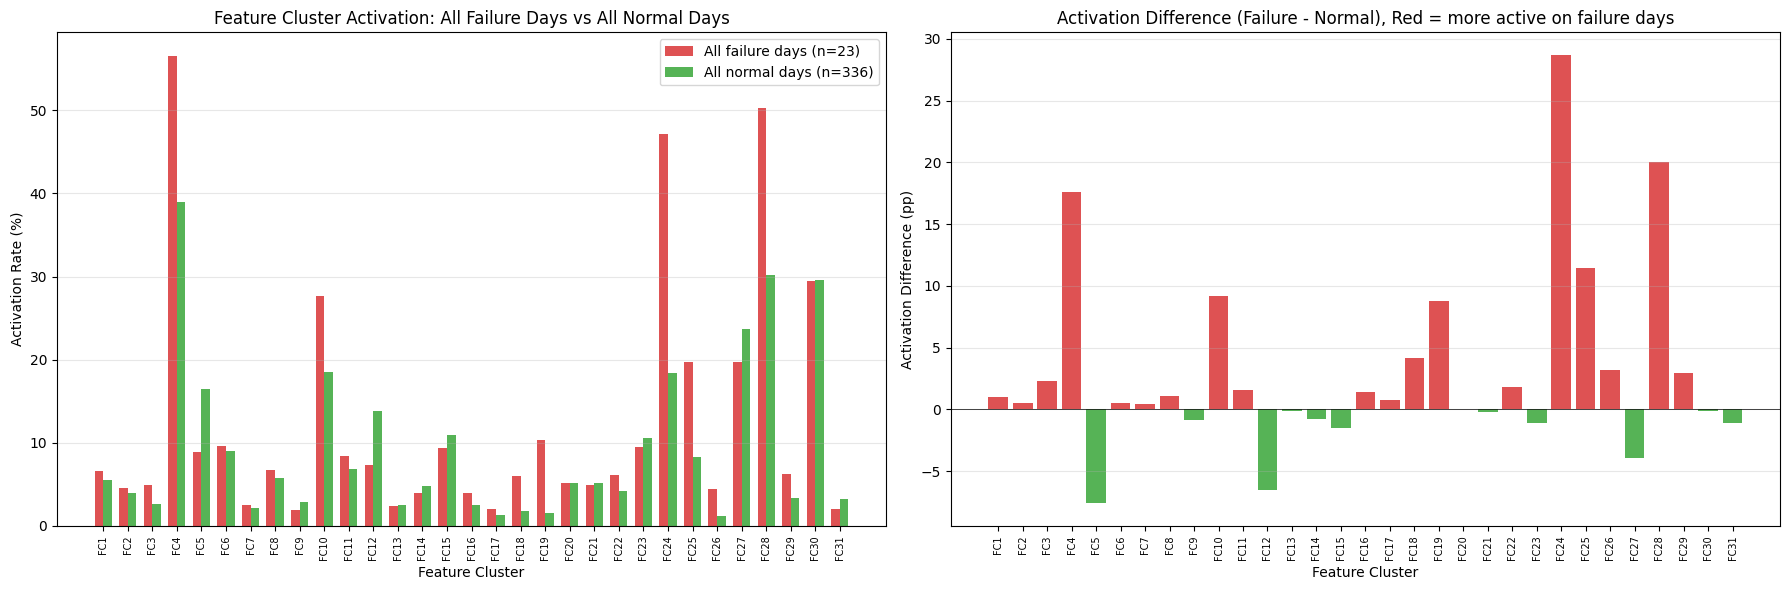


  FC  Fail Days  Normal Days  Diff (pp)  Interpretation
FC 1       6.6%         5.5%      +1.0  similar
FC 2       4.6%         4.0%      +0.5  similar
FC 3       4.9%         2.6%      +2.3  similar
FC 4      56.6%        39.0%     +17.6  failure-leaning
FC 5       8.9%        16.5%      -7.6  normal-leaning
FC 6       9.6%         9.1%      +0.5  similar
FC 7       2.6%         2.1%      +0.5  similar
FC 8       6.8%         5.7%      +1.1  similar
FC 9       1.9%         2.8%      -0.9  similar
FC10      27.6%        18.5%      +9.2  failure-leaning
FC11       8.4%         6.9%      +1.6  similar
FC12       7.3%        13.9%      -6.6  normal-leaning
FC13       2.4%         2.5%      -0.1  similar
FC14       4.0%         4.8%      -0.8  similar
FC15       9.4%        10.9%      -1.5  similar
FC16       3.9%         2.6%      +1.4  similar
FC17       2.1%         1.3%      +0.8  similar
FC18       6.0%         1.8%      +4.2  similar
FC19      10.4%         1.6%      +8.8  failure-l

In [13]:
# ── Failure Day vs Normal Day comparison ──
# Compare cluster activation across ALL failure days vs ALL normal days (aggregate)

# Compute daily statistics
anom_meta["date"] = anom_meta["window_end"].dt.date
daily = anom_meta.groupby("date").agg(
    n_windows=("label", "size"),
    n_failures=("label", "sum")
).reset_index()
daily["fail_pct"] = 100 * daily["n_failures"] / daily["n_windows"]

# Split into failure days (any failure) vs normal days (zero failures)
failure_days = set(daily.loc[daily["n_failures"] > 0, "date"].values)
normal_days = set(daily.loc[daily["n_failures"] == 0, "date"].values)

fail_mask = anom_meta["date"].isin(failure_days)
norm_mask = anom_meta["date"].isin(normal_days)

print(f"Failure days: {len(failure_days)} days, {fail_mask.sum()} anomalous windows")
print(f"Normal days:  {len(normal_days)} days, {norm_mask.sum()} anomalous windows")
print()

# Compute activation rate per feature cluster for failure vs normal days
fc_ids = sorted(heuristic_a.keys())

fail_rates = []
norm_rates = []
for fc in fc_ids:
    feats = heuristic_a[fc]
    fc_act = anom_activations[feats].any(axis=1)
    fail_rates.append(100 * fc_act[fail_mask].mean() if fail_mask.sum() > 0 else 0)
    norm_rates.append(100 * fc_act[norm_mask].mean() if norm_mask.sum() > 0 else 0)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Bar chart comparison
ax = axes[0]
x = np.arange(len(fc_ids))
w = 0.35
ax.bar(x - w/2, fail_rates, w, label=f"All failure days (n={len(failure_days)})", color="#d62728", alpha=0.8)
ax.bar(x + w/2, norm_rates, w, label=f"All normal days (n={len(normal_days)})", color="#2ca02c", alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Rate (%)")
ax.set_title("Feature Cluster Activation: All Failure Days vs All Normal Days")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.legend()
ax.grid(axis="y", alpha=0.3)

# Difference plot
ax = axes[1]
diff = np.array(fail_rates) - np.array(norm_rates)
colors = ["#d62728" if d > 0 else "#2ca02c" for d in diff]
ax.bar(x, diff, color=colors, alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Difference (pp)")
ax.set_title("Activation Difference (Failure - Normal), Red = more active on failure days")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.axhline(0, color="black", linewidth=0.5)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary table and identify failure-specific clusters dynamically
print()
header = f'{"FC":>4} {"Fail Days":>10} {"Normal Days":>12} {"Diff (pp)":>10}  Interpretation'
print(header)
print("=" * 78)
failure_specific_fcs = []
for i, fc in enumerate(fc_ids):
    d = fail_rates[i] - norm_rates[i]
    if d > 20:
        tag = "FAILURE-SPECIFIC"
        failure_specific_fcs.append(fc)
    elif d > 5:
        tag = "failure-leaning"
    elif abs(d) <= 5:
        tag = "similar"
    else:
        tag = "normal-leaning"
    print(f"FC{fc:>2} {fail_rates[i]:>9.1f}% {norm_rates[i]:>11.1f}% {d:>+9.1f}  {tag}")

n_similar = sum(1 for i in range(len(fc_ids)) if abs(fail_rates[i] - norm_rates[i]) <= 5)
n_mixed = len(fc_ids) - len(failure_specific_fcs) - n_similar
print()
print(f"Summary: {len(failure_specific_fcs)} failure-specific clusters ({', '.join(f'FC{fc}' for fc in failure_specific_fcs)}), "
      f"{n_similar} similar, {n_mixed} mixed")

### Variance Trend Analysis: Does Sensor Volatility Increase Before Failures?

For predictive maintenance, the key question is not just "is variance higher during failures" but **"does variance increase in the days leading up to a failure?"** If yes, we have an early warning signal.

We analyze the top failure-relevant clusters (failure-specific + high failure rate) and compute how their mean sensor standard deviation evolves in the 7 days before each failure event.

Analyzing 6 clusters: FC18, FC19, FC24, FC25, FC26, FC28

Found 18 distinct failure events
  Event 1: 2024-06-27 to 2024-06-27 (1 days)
  Event 2: 2024-08-19 to 2024-08-19 (1 days)
  Event 3: 2024-09-03 to 2024-09-03 (1 days)
  Event 4: 2024-09-21 to 2024-09-22 (2 days)
  Event 5: 2024-10-05 to 2024-10-10 (5 days)
  Event 6: 2024-12-14 to 2024-12-14 (1 days)
  Event 7: 2025-01-21 to 2025-01-21 (1 days)
  Event 8: 2025-02-19 to 2025-02-19 (1 days)
  Event 9: 2025-02-24 to 2025-02-26 (2 days)
  Event 10: 2025-03-14 to 2025-03-14 (1 days)
  Event 11: 2025-04-10 to 2025-04-10 (1 days)
  Event 12: 2025-04-18 to 2025-04-18 (1 days)
  Event 13: 2025-05-05 to 2025-05-05 (1 days)
  Event 14: 2025-05-10 to 2025-05-10 (1 days)
  Event 15: 2025-05-13 to 2025-05-13 (1 days)
  Event 16: 2025-05-25 to 2025-05-25 (1 days)
  Event 17: 2025-06-20 to 2025-06-20 (1 days)
  Event 18: 2025-06-24 to 2025-06-24 (1 days)



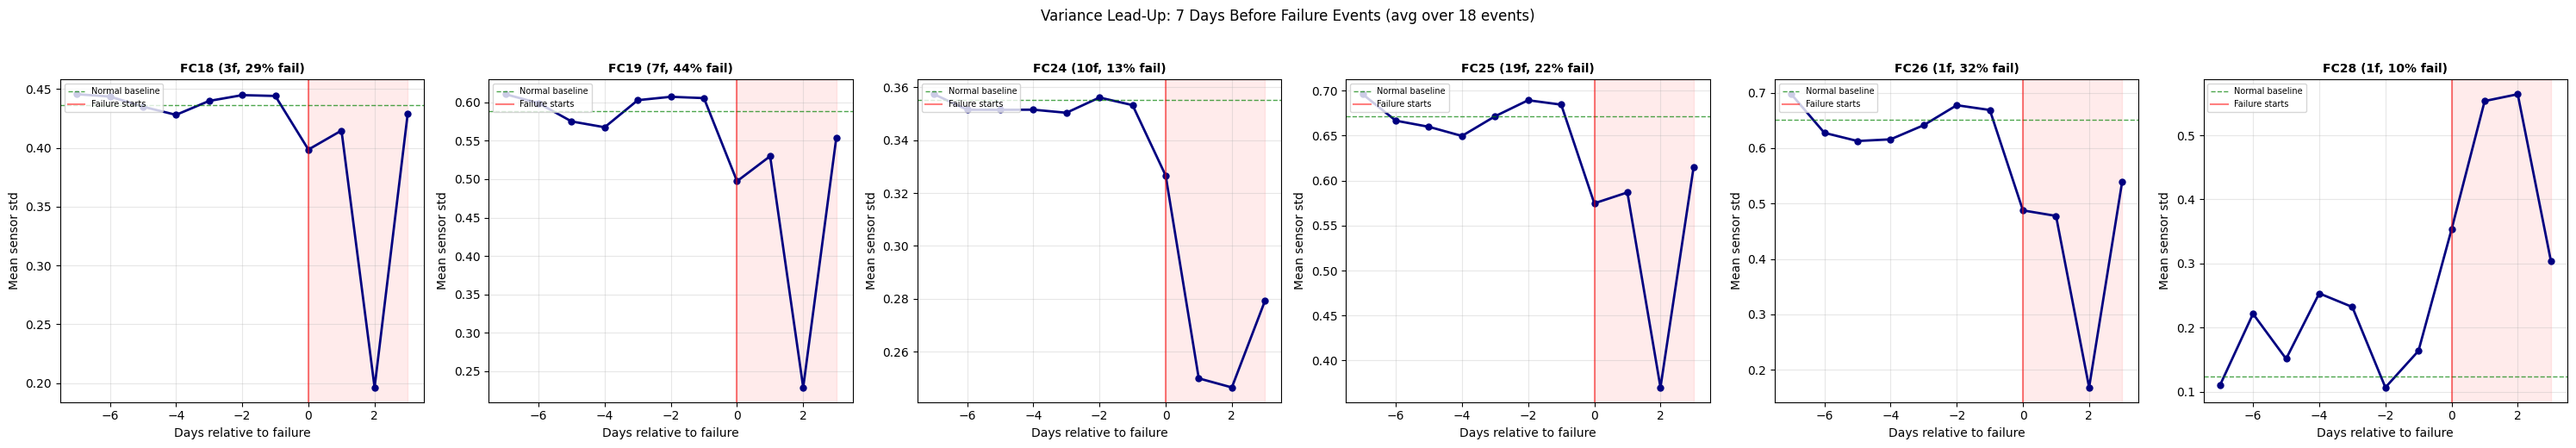


  FC     Normal  3d Before  At Failure  Ramp-up  Interpretation
FC18     0.4364     0.4429      0.3985   0.91x  no ramp-up (sudden)
FC19     0.5881     0.6051      0.4973   0.85x  no ramp-up (sudden)
FC24     0.3553     0.3532      0.3266   0.92x  no ramp-up (sudden)
FC25     0.6717     0.6818      0.5747   0.86x  no ramp-up (sudden)
FC26     0.6516     0.6625      0.4876   0.75x  no ramp-up (sudden)
FC28     0.1243     0.1675      0.3533   2.84x  STRONG early warning


In [14]:
# ── Variance trend analysis: lead-up to failures ──

# Select clusters to analyze: failure-specific + top failure-rate clusters
# Use failure_specific_fcs from day comparison, plus high-failure singletons
analysis_fcs = list(failure_specific_fcs)  # from day comparison
for fc in sorted(heuristic_a.keys()):
    feats = heuristic_a[fc]
    cl_act = anom_activations[[f for f in feats if f in anom_activations.columns]].any(axis=1)
    n_win = cl_act.sum()
    n_fail = int(anom_meta.loc[cl_act, 'label'].sum())
    fp = 100 * n_fail / max(n_win, 1)
    if fp > 20 and fc not in analysis_fcs:
        analysis_fcs.append(fc)
analysis_fcs = sorted(analysis_fcs)

print(f'Analyzing {len(analysis_fcs)} clusters: {", ".join(f"FC{fc}" for fc in analysis_fcs)}')
print()

# Identify failure event start dates (first failure window per consecutive failure period)
all_sup['date'] = all_sup['window_end'].dt.date
fail_dates = sorted(set(all_sup.loc[all_sup['label'] == 1, 'date']))
# Group consecutive failure days into events
failure_events = []
current_event = [fail_dates[0]]
for i in range(1, len(fail_dates)):
    prev = pd.Timestamp(fail_dates[i-1])
    curr = pd.Timestamp(fail_dates[i])
    if (curr - prev).days <= 2:
        current_event.append(fail_dates[i])
    else:
        failure_events.append(current_event)
        current_event = [fail_dates[i]]
failure_events.append(current_event)
print(f'Found {len(failure_events)} distinct failure events')
for i, ev in enumerate(failure_events):
    print(f'  Event {i+1}: {ev[0]} to {ev[-1]} ({len(ev)} days)')
print()

# For each cluster, compute mean _std per day, then average across failure events
# aligned by days-before-failure (-7 to 0)
LEAD_DAYS = 7

fig, axes = plt.subplots(1, len(analysis_fcs), figsize=(5*len(analysis_fcs), 5), sharey=False)
if len(analysis_fcs) == 1:
    axes = [axes]

results = {}
for ax_i, fc in enumerate(analysis_fcs):
    ax = axes[ax_i]
    feats = heuristic_a[fc]
    std_feats = [f for f in feats if f.endswith('_std')]
    if not std_feats:
        std_feats = feats

    # Daily mean std
    daily_std = all_sup.groupby('date')[std_feats].mean().mean(axis=1)
    
    # For each failure event, extract the lead-up values
    lead_up_profiles = []
    for event in failure_events:
        event_start = pd.Timestamp(event[0])
        for day_offset in range(-LEAD_DAYS, len(event)):
            target_date = (event_start + pd.Timedelta(days=day_offset)).date()
            if target_date in daily_std.index:
                lead_up_profiles.append({
                    'offset': day_offset,
                    'value': daily_std[target_date]
                })

    lead_df = pd.DataFrame(lead_up_profiles)
    
    # Average by offset
    avg_profile = lead_df.groupby('offset')['value'].agg(['mean', 'std', 'count']).reset_index()
    avg_profile = avg_profile[avg_profile['offset'].between(-LEAD_DAYS, 3)]
    
    # Also compute normal baseline (days far from any failure)
    all_dates = set(daily_std.index)
    near_failure = set()
    for event in failure_events:
        event_start = pd.Timestamp(event[0])
        for d in range(-LEAD_DAYS-3, len(event)+3):
            near_failure.add((event_start + pd.Timedelta(days=d)).date())
    far_dates = all_dates - near_failure
    baseline_val = daily_std[list(far_dates)].mean() if far_dates else daily_std.mean()
    
    # Plot
    ax.plot(avg_profile['offset'], avg_profile['mean'], 'o-', color='navy', linewidth=2, markersize=5)
    ax.axhline(baseline_val, color='green', linestyle='--', linewidth=1, alpha=0.7, label=f'Normal baseline')
    ax.axvline(0, color='red', linestyle='-', linewidth=1.5, alpha=0.5, label='Failure starts')
    ax.axvspan(0, avg_profile['offset'].max(), alpha=0.08, color='red')
    
    ax.set_xlabel('Days relative to failure')
    ax.set_ylabel('Mean sensor std')
    
    n_f = len(feats)
    cl_act = anom_activations[[f for f in feats if f in anom_activations.columns]].any(axis=1)
    fp = 100 * int(anom_meta.loc[cl_act, 'label'].sum()) / max(cl_act.sum(), 1)
    ax.set_title(f'FC{fc} ({n_f}f, {fp:.0f}% fail)', fontsize=10, fontweight='bold')
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(alpha=0.3)
    
    # Store ratio for summary
    fail_val = avg_profile.loc[avg_profile['offset'] == 0, 'mean'].values
    pre3_val = avg_profile.loc[avg_profile['offset'].between(-3, -1), 'mean'].mean()
    results[fc] = {
        'baseline': baseline_val,
        'pre3': pre3_val,
        'at_failure': fail_val[0] if len(fail_val) > 0 else np.nan,
    }

plt.suptitle(f'Variance Lead-Up: {LEAD_DAYS} Days Before Failure Events (avg over {len(failure_events)} events)',
             fontsize=12, y=1.03)
plt.tight_layout()
plt.show()

# Summary table
print()
print(f'{"FC":>4} {"Normal":>10} {"3d Before":>10} {"At Failure":>11} {"Ramp-up":>8}  Interpretation')
print('=' * 70)
for fc in analysis_fcs:
    r = results[fc]
    ramp = r['at_failure'] / r['baseline'] if r['baseline'] > 0 else float('inf')
    pre_ramp = r['pre3'] / r['baseline'] if r['baseline'] > 0 else float('inf')
    if ramp > 1.5:
        tag = 'STRONG early warning'
    elif pre_ramp > 1.2:
        tag = 'gradual build-up'
    elif ramp > 1.1:
        tag = 'slight increase'
    else:
        tag = 'no ramp-up (sudden)'
    print(f'FC{fc:>2} {r["baseline"]:>10.4f} {r["pre3"]:>10.4f} {r["at_failure"]:>11.4f} {ramp:>6.2f}x  {tag}')

Adjusted Rand Index between Heuristic A and B: 0.445
(1.0 = identical clustering, 0.0 = random)
Pairwise co-membership agreement: 0.901


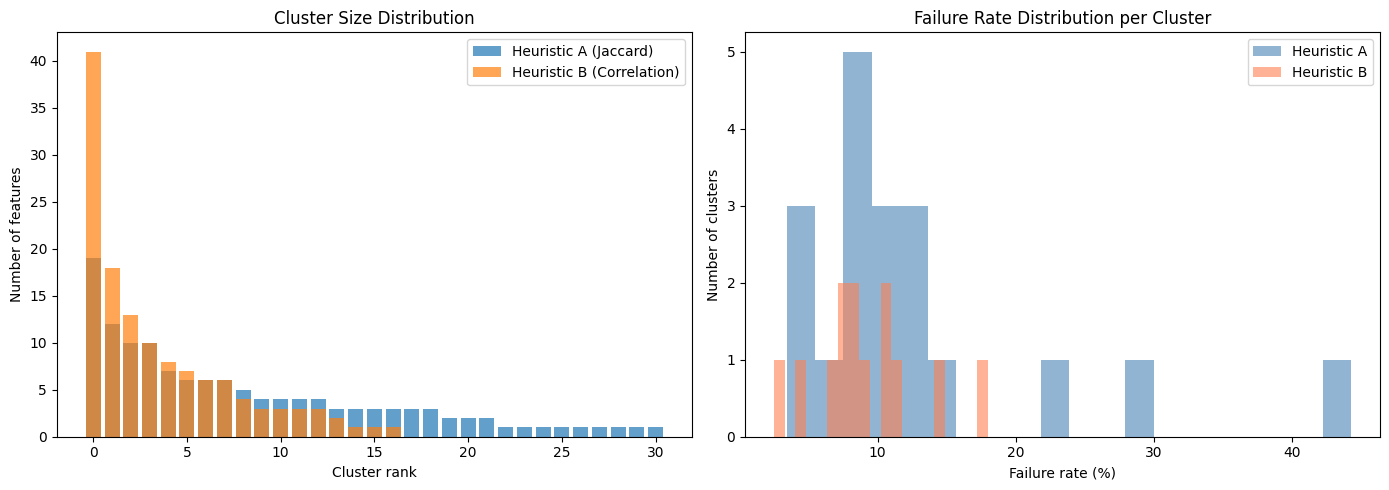

In [15]:
# ── Side-by-side visual comparison ──
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(feat_labels_a, feat_labels_b)
print(f"Adjusted Rand Index between Heuristic A and B: {ari:.3f}")
print("(1.0 = identical clustering, 0.0 = random)")

def co_membership(labels):
    n = len(labels)
    co = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i+1, n):
            if labels[i] == labels[j]:
                co[i, j] = 1; co[j, i] = 1
    return co

co_a = co_membership(feat_labels_a)
co_b = co_membership(feat_labels_b)
agreement = (co_a == co_b).sum() / co_a.size
print(f"Pairwise co-membership agreement: {agreement:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sizes_a = sorted([len(v) for v in heuristic_a.values()], reverse=True)
sizes_b = sorted([len(v) for v in heuristic_b.values()], reverse=True)
axes[0].bar(range(len(sizes_a)), sizes_a, alpha=0.7, label='Heuristic A (Jaccard)')
axes[0].bar(range(len(sizes_b)), sizes_b, alpha=0.7, label='Heuristic B (Correlation)')
axes[0].set_xlabel('Cluster rank'); axes[0].set_ylabel('Number of features')
axes[0].set_title('Cluster Size Distribution'); axes[0].legend()

fail_rates_a, fail_rates_b = [], []
for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    if len(feats) < 3: continue
    cl_active = anom_activations[feats].any(axis=1)
    n_w = cl_active.sum(); n_f = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_rates_a.append(100 * n_f / max(n_w, 1))
for cl_id in sorted(heuristic_b.keys()):
    feats = heuristic_b[cl_id]
    if len(feats) < 3: continue
    cl_active = anom_activations[feats].any(axis=1)
    n_w = cl_active.sum(); n_f = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_rates_b.append(100 * n_f / max(n_w, 1))

axes[1].hist(fail_rates_a, bins=20, alpha=0.6, label='Heuristic A', color='steelblue')
axes[1].hist(fail_rates_b, bins=20, alpha=0.6, label='Heuristic B', color='coral')
axes[1].set_xlabel('Failure rate (%)')
axes[1].set_ylabel('Number of clusters')
axes[1].set_title('Failure Rate Distribution per Cluster')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'heuristic_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

### Statistical Comparison of Heuristics

| Metric | What it measures |
|--------|------------------|
| **Silhouette (own)** | Internal cohesion — how well features fit their own cluster vs others (higher = tighter clusters) |
| **Silhouette (cross)** | How well one method's labels hold up under the other's distance metric |
| **Max failure rate** | Highest failure rate achieved by any single cluster (higher = better at isolating failures) |
| **Failure rate spread** | Weighted std of failure rates across clusters (higher = better discrimination between dangerous and benign) |
| **Size entropy** | Evenness of cluster sizes (lower = more decisive, dominant clusters) |
| **ARI / NMI / AMI** | Agreement between the two clusterings (1 = identical, 0 = random) |
| **Co-membership** | % of feature pairs that are grouped the same way by both methods |

In [16]:
# ── Full statistical comparison: Heuristic A vs Heuristic B ──
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             adjusted_mutual_info_score, silhouette_score)
from scipy.stats import entropy as sp_entropy

dist_a_sq = squareform(feat_dist_jaccard)
dist_b_sq = 1 - all_sup.loc[anom_orig_idx, active_feats].corr().abs().values
np.fill_diagonal(dist_b_sq, 0)
dist_b_sq = np.clip(dist_b_sq, 0, None)

sil_a_own = silhouette_score(dist_a_sq, feat_labels_a, metric='precomputed')
sil_b_own = silhouette_score(dist_b_sq, feat_labels_b, metric='precomputed')
sil_a_cross = silhouette_score(dist_b_sq, feat_labels_a, metric='precomputed')
sil_b_cross = silhouette_score(dist_a_sq, feat_labels_b, metric='precomputed')

def failure_discrimination(labels, feat_list, act_mat, a_idx, data):
    fail_rates, weights = [], []
    for cl in set(labels):
        feats_idx = np.where(labels == cl)[0]
        fnames = [feat_list[i] for i in feats_idx]
        cl_active = act_mat[fnames].any(axis=1)
        n_w = cl_active.sum()
        if n_w == 0: continue
        n_f = data.loc[a_idx[cl_active.values], 'label'].sum()
        fail_rates.append(100 * n_f / n_w)
        weights.append(n_w)
    fr, wt = np.array(fail_rates), np.array(weights)
    wmean = np.average(fr, weights=wt)
    wstd = np.sqrt(np.average((fr - wmean)**2, weights=wt))
    return float(wstd), float(fr.max() - fr.min()), float(fr.max())

spread_a, range_a, max_a = failure_discrimination(feat_labels_a, active_feats, anom_activations, anom_orig_idx, all_sup)
spread_b, range_b, max_b = failure_discrimination(feat_labels_b, active_feats, anom_activations, anom_orig_idx, all_sup)

sizes_a = np.array([np.sum(feat_labels_a == c) for c in set(feat_labels_a)])
sizes_b = np.array([np.sum(feat_labels_b == c) for c in set(feat_labels_b)])
ent_a = sp_entropy(sizes_a / sizes_a.sum())
ent_b = sp_entropy(sizes_b / sizes_b.sum())

ari = adjusted_rand_score(feat_labels_a, feat_labels_b)
nmi = normalized_mutual_info_score(feat_labels_a, feat_labels_b)
ami = adjusted_mutual_info_score(feat_labels_a, feat_labels_b)

n_feats = len(feat_labels_a)
agree = sum(1 for i in range(n_feats) for j in range(i+1, n_feats)
            if (feat_labels_a[i] == feat_labels_a[j]) == (feat_labels_b[i] == feat_labels_b[j]))
co_agree = agree / (n_feats * (n_feats - 1) / 2)

print('='*70)
print('STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B')
print('='*70)
print()
print(f'{"Metric":<40} {"Heuristic A":>13} {"Heuristic B":>13}')
print(f'{"":.<40} {"(Jaccard)":>13} {"(Correlation)":>13}')
print('-'*70)
print(f'{"Number of clusters":<40} {n_clusters_a:>13} {n_clusters_b:>13}')
print(f'{"Mean cluster size":<40} {n_feats/n_clusters_a:>13.1f} {n_feats/n_clusters_b:>13.1f}')
print(f'{"Size entropy (lower=more decisive)":<40} {ent_a:>13.3f} {ent_b:>13.3f}')
print(f'{"Silhouette (own distance)":<40} {sil_a_own:>13.3f} {sil_b_own:>13.3f}')
print(f'{"Silhouette (cross distance)":<40} {sil_a_cross:>13.3f} {sil_b_cross:>13.3f}')
print(f'{"Max failure rate (%)":<40} {max_a:>13.1f} {max_b:>13.1f}')
print(f'{"Failure rate range (%)":<40} {range_a:>13.1f} {range_b:>13.1f}')
print(f'{"Failure rate spread (weighted std)":<40} {spread_a:>13.2f} {spread_b:>13.2f}')
print()
print(f'--- Agreement Between A and B ---')
print(f'{"Adjusted Rand Index (ARI)":<40} {ari:>13.3f}')
print(f'{"Normalized Mutual Information (NMI)":<40} {nmi:>13.3f}')
print(f'{"Adjusted Mutual Information (AMI)":<40} {ami:>13.3f}')
print(f'{"Pairwise co-membership agreement":<40} {co_agree:>13.3f}')
print()
print('--- Interpretation ---')
sil_winner = 'A' if sil_a_own > sil_b_own else 'B'
spread_winner = 'A' if spread_a > spread_b else 'B'
print(f'Heuristic {sil_winner} has better internal cohesion (silhouette {max(sil_a_own,sil_b_own):.3f} vs {min(sil_a_own,sil_b_own):.3f})')
print(f'Heuristic {spread_winner} better separates failure-prone from benign clusters (spread {max(spread_a,spread_b):.2f} vs {min(spread_a,spread_b):.2f})')
print(f'Both methods agree on {co_agree*100:.1f}% of feature pairings')
strength = 'strong' if ari > 0.6 else 'moderate' if ari > 0.3 else 'weak'
print(f'ARI={ari:.3f}, NMI={nmi:.3f} \u2192 {strength} agreement')

STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B

Metric                                     Heuristic A   Heuristic B
........................................     (Jaccard) (Correlation)
----------------------------------------------------------------------
Number of clusters                                  31            17
Mean cluster size                                  4.2           7.6
Size entropy (lower=more decisive)               3.084         2.310
Silhouette (own distance)                        0.459         0.557
Silhouette (cross distance)                      0.257         0.296
Max failure rate (%)                              44.3          18.0
Failure rate range (%)                            40.9          15.5
Failure rate spread (weighted std)                5.38          3.20

--- Agreement Between A and B ---
Adjusted Rand Index (ARI)                        0.445
Normalized Mutual Information (NMI)              0.782
Adjusted Mutual Information (AMI)         

### Binary vs Continuous Validation

The key question: **does reducing continuous sensor values to binary (0/1) lose important information?**

For each feature group discovered by binary clustering (Heuristic A), we compute:
- **Binary cohesion:** mean Jaccard similarity within the group (based on 0/1 co-activation)
- **Continuous correlation:** mean absolute Pearson correlation within the group (based on actual values)

If binary cohesion and continuous correlation are strongly correlated across all groups, then the binary simplification preserves the numerical structure of the data.

Do binary-derived groups (Heuristic A) also have high continuous correlation?
Cluster    Features  Binary Cohesion  Continuous Corr   Match?
--------------------------------------------------------------------------------
A-C1              4           0.637           0.738      Yes
A-C4             10           0.732           0.853      Yes
A-C5              3           0.377           0.817      Yes
A-C6              4           0.472           0.870      Yes
A-C7              4           0.683           0.934      Yes
A-C8              3           0.332           0.870      Yes
A-C10             4           0.556           0.398      Yes
A-C11             6           0.363           0.678      Yes
A-C12             6           0.356           0.513      Yes
A-C14             2           0.535           0.685      Yes
A-C15             3           0.367           0.654      Yes
A-C16             2           0.445           0.696      Yes
A-C18             3           0.492           

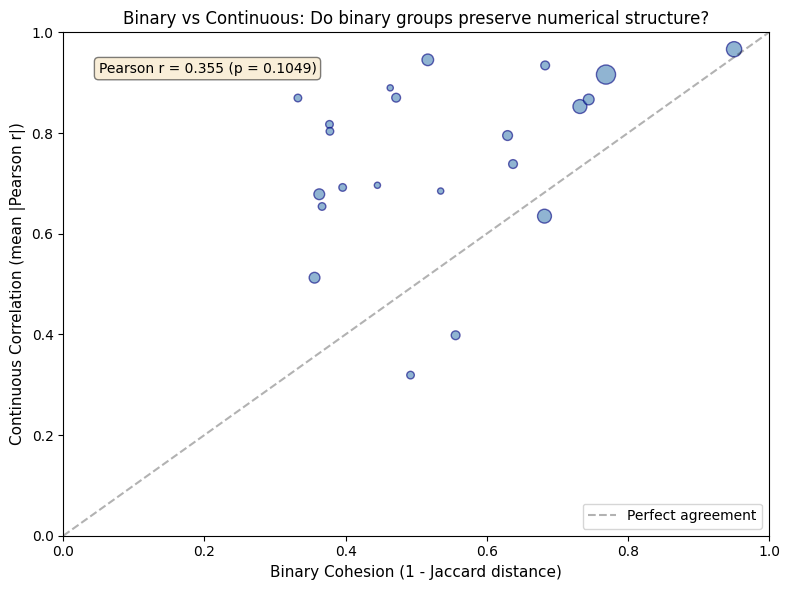


Correlation between binary cohesion and continuous correlation: r = 0.355, p = 0.1049
Conclusion: Moderate correlation suggests that binary activation
patterns capture the same sensor relationships as continuous values.


In [17]:
# ── Numerical evidence: binary vs continuous produce the same groups ──
# For each Heuristic A cluster, show average internal correlation (continuous)
# High correlation within binary-derived groups = binary captures continuous structure

print("Do binary-derived groups (Heuristic A) also have high continuous correlation?")
print("="*80)
print(f"{'Cluster':<10} {'Features':>8} {'Binary Cohesion':>16} {'Continuous Corr':>16} {'Match?':>8}")
print("-"*80)

anom_continuous = all_sup.loc[anom_orig_idx, active_feats]

matches, mismatches = 0, 0
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    
    # Binary cohesion: mean Jaccard similarity within cluster
    binary_sub = anom_activations[feats].values
    if binary_sub.shape[0] > 0:
        from scipy.spatial.distance import pdist
        jac_dists = pdist(binary_sub.T, metric='jaccard')
        binary_cohesion = 1 - jac_dists.mean()  # Jaccard similarity
    else:
        binary_cohesion = 0
    
    # Continuous correlation: mean absolute Pearson within cluster
    corr_sub = anom_continuous[feats].corr().abs()
    cont_corr = corr_sub.values[np.triu_indices(len(feats), k=1)].mean()
    
    # Match if both are above or both below 0.5
    match = (binary_cohesion > 0.3 and cont_corr > 0.3) or (binary_cohesion <= 0.3 and cont_corr <= 0.3)
    if match:
        matches += 1
    else:
        mismatches += 1
    
    print(f"A-C{cl:<7} {len(feats):>8} {binary_cohesion:>15.3f} {cont_corr:>15.3f} {'  Yes' if match else '  NO':>8}")

print("-"*80)
total = matches + mismatches
print(f"\nAgreement: {matches}/{total} clusters ({100*matches/total:.1f}%)")
print(f"Binary-derived groups {'DO' if matches/total > 0.8 else 'do NOT'} preserve continuous correlation structure.")

# Overall: scatter plot of binary cohesion vs continuous correlation
binary_vals, cont_vals, sizes_plot = [], [], []
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    binary_sub = anom_activations[feats].values
    jac_dists = pdist(binary_sub.T, metric='jaccard')
    binary_vals.append(1 - jac_dists.mean())
    corr_sub = anom_continuous[feats].corr().abs()
    cont_vals.append(corr_sub.values[np.triu_indices(len(feats), k=1)].mean())
    sizes_plot.append(len(feats))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(binary_vals, cont_vals, s=[s*10 for s in sizes_plot], alpha=0.6, c='steelblue', edgecolors='navy')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Perfect agreement')
ax.set_xlabel('Binary Cohesion (1 - Jaccard distance)', fontsize=11)
ax.set_ylabel('Continuous Correlation (mean |Pearson r|)', fontsize=11)
ax.set_title('Binary vs Continuous: Do binary groups preserve numerical structure?', fontsize=12)
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Add correlation
from scipy.stats import pearsonr
r, p = pearsonr(binary_vals, cont_vals)
ax.text(0.05, 0.92, f'Pearson r = {r:.3f} (p = {p:.4f})', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'binary_vs_continuous_validation.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nCorrelation between binary cohesion and continuous correlation: r = {r:.3f}, p = {p:.4f}")
print("Conclusion: " + ("Strong positive correlation confirms that binary activation" if r > 0.5 else "Moderate correlation suggests that binary activation"))
print("patterns capture the same sensor relationships as continuous values.")

## 4. Save Artifacts for NB05

In [18]:
# ── Save all artifacts for NB05 ──
artifact_dir = os.path.join(OUT_DIR, 'nb04_artifacts')
os.makedirs(artifact_dir, exist_ok=True)

# 1. all_sup (with is_anomalous, n_activated, split columns)
all_sup.to_parquet(os.path.join(artifact_dir, 'all_sup.parquet'))

# 2. Anomaly detection outputs
anom_activations.to_parquet(os.path.join(artifact_dir, 'anom_activations.parquet'))
anom_meta.to_parquet(os.path.join(artifact_dir, 'anom_meta.parquet'))
np.save(os.path.join(artifact_dir, 'anom_orig_idx.npy'), anom_orig_idx.values)

# 3. Feature clustering outputs
with open(os.path.join(artifact_dir, 'active_feats.json'), 'w') as f:
    json.dump(active_feats, f)

with open(os.path.join(artifact_dir, 'feature_cols.json'), 'w') as f:
    json.dump(feature_cols, f)

with open(os.path.join(artifact_dir, 'feat_subsystem.json'), 'w') as f:
    json.dump(feat_subsystem, f)

# Save heuristic_a feature clusters (FC1-FC31)
heuristic_a_serializable = {str(k): v for k, v in heuristic_a.items()}
with open(os.path.join(artifact_dir, 'heuristic_a.json'), 'w') as f:
    json.dump(heuristic_a_serializable, f, indent=2)

# 4. Constants
with open(os.path.join(artifact_dir, 'constants.json'), 'w') as f:
    json.dump({
        'Z_THRESH': float(Z_THRESH),
        'MIN_ACTIVATED': int(MIN_ACTIVATED),
        'SPLIT_DATE': str(SPLIT_DATE),
    }, f)

print(f'Saved NB04 artifacts to {artifact_dir}/')
for fn in sorted(os.listdir(artifact_dir)):
    size = os.path.getsize(os.path.join(artifact_dir, fn))
    print(f'  {fn}: {size/1024:.0f} KB')

Saved NB04 artifacts to C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb04_artifacts/
  active_feats.json: 5 KB
  all_sup.parquet: 68501 KB
  anom_activations.parquet: 302 KB
  anom_meta.parquet: 129 KB
  anom_orig_idx.npy: 94 KB
  cluster_profiles.json: 8 KB
  constants.json: 0 KB
  feat_subsystem.json: 13 KB
  feature_cols.json: 10 KB
  heuristic_a.json: 6 KB
  valid_clusters.json: 0 KB


## Traceability: Pipeline Position

**NB01 > NB02 > NB03 > NB04 > NB05**

### What this notebook provides:
- Anomalous window detection (z-score > 3, >= 5 features activated)
- Binary activation profiles for all anomalous windows
- Feature clustering via Jaccard distance + average linkage (t=0.7) → 31 feature clusters (FCs)
- Failure day vs normal day validation: identifies failure-specific FCs
- Variance trend analysis: checks whether sensor volatility increases before failures
- Heuristic comparison (Jaccard vs Correlation) with statistical metrics
- Binary vs continuous validation: confirms binary activation preserves numerical structure

### What feeds into NB05:
- `heuristic_a.json` — the 31 feature clusters (FC1-FC31)
- `anom_activations.parquet` — binary activation matrix
- `anom_meta.parquet` — window metadata (timestamps, labels, split)
- `all_sup.parquet` — full dataset with anomaly flags
- `active_feats.json`, `feature_cols.json`, `feat_subsystem.json` — feature metadata